# BeeSkilled — Machine Learning & AI
## Week 1: ML Fundamentals + Data Preprocessing
**Name:** Raman

**Focus:** Basics of ML, Data Cleaning, Feature Engineering

**Topics covered:** What is Machine Learning (Supervised, Unsupervised, Reinforcement) · Importing & exploring datasets · Handling missing data, encoding, scaling · Train/Test Split

This notebook completes:
- **Assignment 1** – Load a dataset using Pandas and summarize basic stats (`.info()`, `.describe()`)
- **Assignment 2** – Handle missing data using mean/median imputation
- **Assignment 3** – Encode categorical variables using LabelEncoder & OneHotEncoder
- **Mini Project 1** – Titanic Survival Prediction: Data Cleaning Project
- **Practice Set** – Week 1 ML Basics (4 practice questions)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score, accuracy_score

sns.set_style("whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


---
## Assignment 1: Load a dataset using Pandas and summarize basic stats

Dataset used: **Titanic dataset** (the same dataset used in the Mini Project).

In [2]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Basic information about the dataset - columns, data types, non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
# Statistical summary of numerical columns - count, mean, std, min, quartiles, max
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
# Statistical summary of categorical (object) columns
df.describe(include="object")

/tmp/ipykernel_26763/2159305879.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


**Observation:** The dataset has 891 rows and 12 columns. Some columns have missing values
(for example `Age`, `Cabin` and `Embarked`), which we handle in Assignment 2.

---
## Assignment 2: Handle missing data using mean/median imputation

Strategy:
- `Age` → **median** imputation (median is safer than mean here because age has outliers)
- `Fare` → **mean** imputation
- `Embarked` → **mode** (most frequent value), because it is categorical
- `Cabin` → dropped, because more than 75% of its values are missing

In [6]:
# Missing values BEFORE cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [7]:
df2 = df.copy()

# Median imputation for Age
age_median = df2["Age"].median()
df2["Age"] = df2["Age"].fillna(age_median)
print("Age filled with median =", age_median)

# Mean imputation for Fare
fare_mean = df2["Fare"].mean()
df2["Fare"] = df2["Fare"].fillna(fare_mean)
print("Fare filled with mean =", round(fare_mean, 4))

# Mode imputation for Embarked (categorical column)
embarked_mode = df2["Embarked"].mode()[0]
df2["Embarked"] = df2["Embarked"].fillna(embarked_mode)
print("Embarked filled with mode =", embarked_mode)

# Drop Cabin - too many missing values to impute usefully
df2 = df2.drop(columns=["Cabin"])
print("\nDropped column: Cabin")

Age filled with median = 28.0
Fare filled with mean = 32.2042
Embarked filled with mode = S

Dropped column: Cabin


In [8]:
# Missing values AFTER cleaning
print("Missing values after cleaning:")
print(df2.isnull().sum())
print("\nTotal missing values remaining:", int(df2.isnull().sum().sum()))

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Total missing values remaining: 0


---
## Assignment 3: Encode categorical variables using LabelEncoder & OneHotEncoder

- `Sex` has only 2 categories, so **LabelEncoder** is suitable (male = 1, female = 0).
- `Embarked` has 3 categories (C, Q, S) with no natural order, so **OneHotEncoder** is the right choice -
  it creates one separate column per category and avoids giving the model a false order.

In [9]:
df3 = df2.copy()

# --- LabelEncoder on Sex ---
le = LabelEncoder()
df3["Sex"] = le.fit_transform(df3["Sex"])
print("LabelEncoder classes for Sex:", list(le.classes_), "-> female = 0, male = 1")

# --- OneHotEncoder on Embarked ---
ohe = OneHotEncoder(sparse_output=False)
embarked_encoded = ohe.fit_transform(df3[["Embarked"]])
embarked_cols = ["Embarked_" + c for c in ohe.categories_[0]]
embarked_df = pd.DataFrame(embarked_encoded, columns=embarked_cols, index=df3.index)

df3 = pd.concat([df3.drop(columns=["Embarked"]), embarked_df], axis=1)
print("OneHotEncoder created columns:", embarked_cols)

df3.head()

LabelEncoder classes for Sex: ['female', 'male'] -> female = 0, male = 1
OneHotEncoder created columns: ['Embarked_C', 'Embarked_Q', 'Embarked_S']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,0.0,0.0,1.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,1.0,0.0,0.0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,0.0,0.0,1.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,0.0,0.0,1.0
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,0.0,0.0,1.0


---
## Mini Project 1: Titanic Survival Prediction – Data Cleaning Project

**Tasks:**
1. Clean missing data
2. Encode `Sex` and `Embarked` columns
3. Visualize age distribution (Matplotlib/Seaborn)
4. Output cleaned dataset as a new CSV

In [10]:
# Step 1 + 2: Start fresh from the raw dataset, clean it and encode it
titanic = pd.read_csv(url)

print("Missing values in raw Titanic dataset:")
print(titanic.isnull().sum())

Missing values in raw Titanic dataset:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [11]:
# Clean missing data
titanic["Age"] = titanic["Age"].fillna(titanic["Age"].median())          # median imputation
titanic["Fare"] = titanic["Fare"].fillna(titanic["Fare"].mean())         # mean imputation
titanic["Embarked"] = titanic["Embarked"].fillna(titanic["Embarked"].mode()[0])  # mode imputation
titanic = titanic.drop(columns=["Cabin"])  # >75% missing, so dropped

# Encode Sex (LabelEncoder) and Embarked (One-Hot Encoding)
le = LabelEncoder()
titanic["Sex"] = le.fit_transform(titanic["Sex"])
titanic = pd.get_dummies(titanic, columns=["Embarked"], prefix="Embarked", dtype=int)

print("Missing values after cleaning:", int(titanic.isnull().sum().sum()))
titanic.head()

Missing values after cleaning: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,0,0,1
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,0,0,1


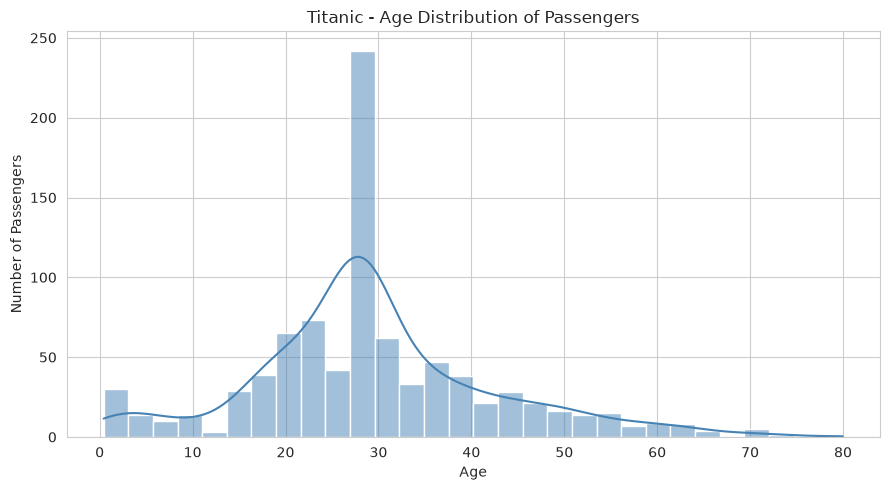

Most passengers were between 20 and 40 years old.


In [12]:
# Step 3: Visualize the age distribution
plt.figure(figsize=(9, 5))
sns.histplot(titanic["Age"], bins=30, kde=True, color="steelblue")
plt.title("Titanic - Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.savefig("age_distribution.png", dpi=150)
plt.show()

print("Most passengers were between 20 and 40 years old.")

In [13]:
# Step 4: Save the cleaned dataset as a new CSV
titanic.to_csv("titanic_cleaned.csv", index=False)
print("Cleaned dataset saved as: titanic_cleaned.csv")
print("Cleaned dataset shape:", titanic.shape)

Cleaned dataset saved as: titanic_cleaned.csv
Cleaned dataset shape: (891, 13)


In [14]:
# Bonus ( connects cleaning to the project title ): a quick Logistic Regression
# on the cleaned data to predict survival
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
            "Embarked_C", "Embarked_Q", "Embarked_S"]
X = titanic[features]
y = titanic["Survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Logistic Regression accuracy on test data:", round(accuracy_score(y_test, pred) * 100, 2), "%")

Logistic Regression accuracy on test data: 81.01 %


---
## Practice Set – Week 1: ML Basics

**Q1.** Load a CSV using pandas and print first 10 rows.
**Q2.** Split dataset into train/test using sklearn.
**Q3.** Train a Linear Regression model and check accuracy.
**Q4.** Predict house price based on area input.

In [15]:
# Q1: Load a CSV using pandas and print the first 10 rows
data = pd.read_csv(url)
data.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [16]:
# Q2: Split the dataset into train/test using sklearn
X = data[["Age", "Fare"]].copy()
X["Age"] = X["Age"].fillna(X["Age"].median())
X["Fare"] = X["Fare"].fillna(X["Fare"].mean())
y = data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))

Training rows: 712
Testing rows : 179


In [17]:
# Q3: Train a Linear Regression model and check its score (R-squared)
lr = LinearRegression()
lr.fit(X_train, y_train)
predictions = lr.predict(X_test)

score = r2_score(y_test, predictions)
print("Linear Regression R-squared score:", round(score, 4))
print("Note: R-squared is low here because survival is a yes/no outcome -")
print("classification models like Logistic Regression (used above) suit it better.")

Linear Regression R-squared score: 0.0967
Note: R-squared is low here because survival is a yes/no outcome -
classification models like Logistic Regression (used above) suit it better.


In [18]:
# Q4: Predict house price based on area input
# Small sample dataset of house area (sq.ft) and price
houses = pd.DataFrame({
    "Area":  [1000, 1500, 2000, 2500, 3000, 3500, 4000],
    "Price": [50,   75,   100,  130,  155,  180,  210]   # price in lakhs
})
print(houses)

house_model = LinearRegression()
house_model.fit(houses[["Area"]], houses["Price"])

area_input = 2800
predicted_price = house_model.predict([[area_input]])
print(f"Predicted price for a {area_input} sq.ft house: Rs. {predicted_price[0]:.2f} lakhs")

   Area  Price
0  1000     50
1  1500     75
2  2000    100
3  2500    130
4  3000    155
5  3500    180
6  4000    210
Predicted price for a 2800 sq.ft house: Rs. 144.54 lakhs


/home/hatch/workspace/goals/automating-beeskilled-assignments-and-skillnexis-daily-tasks/hidden_files/venv2/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


---
## Conclusion

In Week 1 I learned how to load and explore a dataset with Pandas, handle missing values using
mean/median/mode imputation, encode categorical variables with LabelEncoder and OneHotEncoder,
visualize data with Seaborn, split data into train/test sets, and train my first regression models.
The cleaned Titanic dataset is saved as **titanic_cleaned.csv**.